# 02 · Fair-price model (regression)

**Question:** given what a listing *is* and *where* it is, what should it cost per night?

The app uses this "fair price" to tell a guest whether a listing is a good deal (the **Deal** score and the "−15% vs fair" tag).

**Plan**
1. Load the clean table, split train/test
2. Baseline: median price for the same district × stay type
3. Ridge regression (linear)
4. Random Forest
5. XGBoost (+ optional tuning)
6. **Our own neural network (MLP) with a district embedding** (TensorFlow/Keras)
7. Compare all models
8. SHAP: why does the best model predict what it predicts?
9. Out-of-fold fair price for every listing + save

Target: `log(price)`. Metrics: RMSE on log (≈ typical % error), MAE in ₺, R².

In [ ]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()          # repo root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT))
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
for p in (PROCESSED, MODELS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
SEED = 42
import joblib
from sklearn.model_selection import train_test_split, KFold, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

## 1. Load and split

In [ ]:
df_all = pd.read_parquet(PROCESSED / "listings_clean.parquet")
feats = json.load(open(PROCESSED / "feature_lists.json"))
CAT, NUM = feats["cat"], feats["num"]

# Monthly-style rentals (min nights >= 28) price differently; we train on normal stays only
df = df_all[df_all["is_monthly"] == 0].reset_index(drop=True)
X, y = df[CAT + NUM], df["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"train {len(X_train):,} · test {len(X_test):,} · features {len(CAT) + len(NUM)}")

train 13,148 · test 3,288 · features 38


In [ ]:
results = {}   # model name -> metrics on the test set

LOG_MIN, LOG_MAX = y_train.min(), y_train.max()

def evaluate(name, y_true_log, y_pred_log):
    y_pred_log = np.clip(y_pred_log, LOG_MIN, LOG_MAX)   # stop rare wild predictions from exploding in ₺
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    results[name] = {
        "RMSE_log": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE_TRY": mean_absolute_error(y_true, y_pred),
        "MedianAPE_%": np.median(np.abs(y_pred / y_true - 1)) * 100,
        "R2_log": r2_score(y_true_log, y_pred_log),
    }
    print(name, {k: round(v, 3) for k, v in results[name].items()})

## 2. Baseline: district × stay type median
Every model must beat this, otherwise it isn't learning anything useful.

In [ ]:
grp = ["neighbourhood_cleansed", "stay_type"]
train_df = X_train.assign(y=y_train)
med_grp = train_df.groupby(grp)["y"].median()
med_type = train_df.groupby("stay_type")["y"].median()
base_pred = (X_test.join(med_grp.rename("p"), on=grp)["p"]
             .fillna(X_test["stay_type"].map(med_type)).fillna(y_train.median()))
evaluate("Baseline (median)", y_test, base_pred)

Baseline (median) {'RMSE_log': np.float64(0.575), 'MAE_TRY': 2584.74, 'MedianAPE_%': np.float64(34.325), 'R2_log': 0.134}


## 3. Ridge regression
Linear model on one-hot categories + scaled numbers. `RidgeCV` picks the regularisation strength by cross-validation.

In [ ]:
def make_pre(scale=True):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), CAT),
        ("num", StandardScaler() if scale else "passthrough", NUM),
    ])

ridge = Pipeline([("pre", make_pre()), ("model", RidgeCV(alphas=np.logspace(-2, 3, 20)))])
ridge.fit(X_train, y_train)
evaluate("Ridge", y_test, ridge.predict(X_test))
print("chosen alpha:", ridge.named_steps["model"].alpha_)

Ridge {'RMSE_log': np.float64(0.431), 'MAE_TRY': 1951.195, 'MedianAPE_%': np.float64(24.254), 'R2_log': 0.514}
chosen alpha: 0.6951927961775606


## 4. Random Forest

In [ ]:
rf = Pipeline([("pre", make_pre(scale=False)),
               ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                               max_features=0.5, n_jobs=-1, random_state=SEED))])
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test))

Random Forest {'RMSE_log': np.float64(0.336), 'MAE_TRY': 1474.375, 'MedianAPE_%': np.float64(15.514), 'R2_log': 0.705}


## 5. XGBoost

In [ ]:
xgb_params = dict(n_estimators=1200, learning_rate=0.03, max_depth=7, min_child_weight=3,
                  subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
                  tree_method="hist", n_jobs=-1, random_state=SEED)
xgb = Pipeline([("pre", make_pre(scale=False)), ("model", XGBRegressor(**xgb_params))])
xgb.fit(X_train, y_train)
evaluate("XGBoost", y_test, xgb.predict(X_test))

XGBoost {'RMSE_log': np.float64(0.312), 'MAE_TRY': 1386.085, 'MedianAPE_%': np.float64(14.785), 'R2_log': 0.745}


In [ ]:
# Random search over XGBoost settings (~10-20 min). Set to False to skip.
RUN_TUNING = True
xgb_base, xgb_tuned = xgb, None
if RUN_TUNING:
    search = RandomizedSearchCV(
        xgb,
        param_distributions={
            "model__max_depth": [4, 5, 6, 7, 8, 10],
            "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
            "model__min_child_weight": [1, 3, 5, 10],
            "model__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
            "model__colsample_bytree": [0.5, 0.6, 0.7, 0.8, 1.0],
            "model__reg_lambda": [0.5, 1, 2, 5, 10],
        },
        n_iter=25, cv=3, scoring="neg_root_mean_squared_error", random_state=SEED, verbose=1)
    search.fit(X_train, y_train)
    print("best CV RMSE:", -search.best_score_, search.best_params_)
    xgb_tuned = search.best_estimator_
    evaluate("XGBoost (tuned)", y_test, xgb_tuned.predict(X_test))

Fitting 3 folds for each of 25 candidates, totalling 75 fits
best CV RMSE: 0.31825986716273574 {'model__subsample': 0.6, 'model__reg_lambda': 10, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}
XGBoost (tuned) {'RMSE_log': np.float64(0.308), 'MAE_TRY': 1359.633, 'MedianAPE_%': np.float64(14.016), 'R2_log': 0.751}


## 6. Our own neural network (MLP)

Architecture:
- **District → embedding** (a learned 8-number vector per district). Instead of 39 one-hot columns, the network learns which districts behave alike.
- Stay type and room type → one-hot. Numeric features → standardised.
- Concatenate → `256 → 128 → 64 → 1` with ReLU, light Dropout and L2 regularisation.
- Target standardised (mean 0, std 1) for stable training; predictions are converted back. Loss: MSE. Optimiser: Adam. Early stopping on a validation slice of the training set.

If you don't have TensorFlow: `pip install tensorflow`.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)

districts = sorted(df["neighbourhood_cleansed"].unique())
d2i = {d: i for i, d in enumerate(districts)}
SMALL_CATS = ["stay_type", "room_type"]

nn_scaler = StandardScaler().fit(X_train[NUM])
nn_onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train[SMALL_CATS])

def to_inputs(Xp):
    """Two inputs for the network: district index, and the dense (scaled + one-hot) features."""
    dist = Xp["neighbourhood_cleansed"].map(d2i).fillna(0).astype("int32").to_numpy()
    num = np.clip(nn_scaler.transform(Xp[NUM]), -5, 5)   # a few listings are 30+ std devs out
    dense = np.hstack([num, nn_onehot.transform(Xp[SMALL_CATS])]).astype("float32")
    return {"district": dist, "features": dense}

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=SEED)
in_tr, in_val, in_test = to_inputs(X_tr), to_inputs(X_val), to_inputs(X_test)
n_dense = in_tr["features"].shape[1]

# Train on a standardised target (mean 0, std 1). log(price) sits around 8.2, and starting
# from 0 makes the first epochs chase the mean instead of learning patterns.
Y_MEAN, Y_STD = y_tr.mean(), y_tr.std()
to_z = lambda s: ((s - Y_MEAN) / Y_STD).to_numpy()
from_z = lambda z: z * Y_STD + Y_MEAN
print("dense inputs:", n_dense, "· districts:", len(districts))

dense inputs: 44 · districts: 38


In [ ]:
def build_mlp(n_districts, n_dense, emb_dim=8):
    district_in = keras.Input(shape=(), dtype="int32", name="district")
    dense_in = keras.Input(shape=(n_dense,), name="features")
    emb = layers.Embedding(n_districts, emb_dim, name="district_emb")(district_in)
    x = layers.Concatenate()([emb, dense_in])
    l2 = keras.regularizers.l2(1e-4)
    for units, drop in [(256, 0.1), (128, 0.1), (64, 0.0)]:
        x = layers.Dense(units, activation="relu", kernel_regularizer=l2)(x)
        if drop:
            x = layers.Dropout(drop)(x)
    out = layers.Dense(1, name="log_price")(x)
    model = keras.Model([district_in, dense_in], out, name="price_mlp")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return model

mlp = build_mlp(len(districts), n_dense)
mlp.summary()

Model: "price_mlp"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ district            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ district_emb        │ (None, 8)         │        304 │ district[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features            │ (None, 44)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 52)        │          0 │ district_emb[0][… │
│ (Concatenate)       │                   │            │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │     13,568 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │     32,896 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 64)        │      8,256 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_price (Dense)   │ (None, 1)         │         65 │ dense_11[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 55,089 (215.19 KB)

 Trainable params: 55,089 (215.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5),
]
history = mlp.fit(in_tr, to_z(y_tr), validation_data=(in_val, to_z(y_val)),
                  epochs=200, batch_size=128, callbacks=callbacks, verbose=2)
mlp_pred = from_z(mlp.predict(in_test, verbose=0).ravel())
evaluate("MLP (ours)", y_test, mlp_pred)

Epoch 1/200
93/93 - 2s - 20ms/step - loss: 0.5800 - mae: 0.5401 - val_loss: 0.4854 - val_mae: 0.4767 - learning_rate: 0.0010
Epoch 2/200
93/93 - 0s - 3ms/step - loss: 0.4789 - mae: 0.4822 - val_loss: 0.4560 - val_mae: 0.4588 - learning_rate: 0.0010
Epoch 3/200
93/93 - 0s - 3ms/step - loss: 0.4408 - mae: 0.4598 - val_loss: 0.4316 - val_mae: 0.4430 - learning_rate: 0.0010
Epoch 4/200
93/93 - 0s - 3ms/step - loss: 0.4165 - mae: 0.4462 - val_loss: 0.4228 - val_mae: 0.4402 - learning_rate: 0.0010
Epoch 5/200
93/93 - 0s - 3ms/step - loss: 0.3978 - mae: 0.4360 - val_loss: 0.4149 - val_mae: 0.4360 - learning_rate: 0.0010
Epoch 6/200
93/93 - 0s - 3ms/step - loss: 0.3825 - mae: 0.4250 - val_loss: 0.4121 - val_mae: 0.4327 - learning_rate: 0.0010
Epoch 7/200
93/93 - 0s - 3ms/step - loss: 0.3673 - mae: 0.4174 - val_loss: 0.4049 - val_mae: 0.4299 - learning_rate: 0.0010
Epoch 8/200
93/93 - 0s - 3ms/step - loss: 0.3568 - mae: 0.4092 - val_loss: 0.3968 - val_mae: 0.4199 - learning_rate: 0.0010
Epoch 9

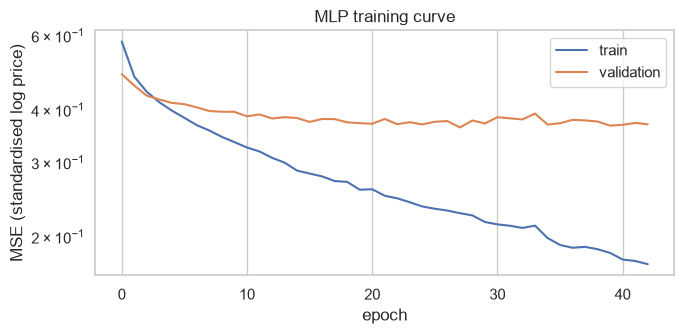

In [ ]:
h = history.history
plt.figure(figsize=(7, 3.5))
plt.plot(h["loss"], label="train"); plt.plot(h["val_loss"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardised log price)"); plt.legend()
plt.title("MLP training curve"); plt.tight_layout(); plt.savefig(FIGS / "mlp_training.png", dpi=120); plt.show()

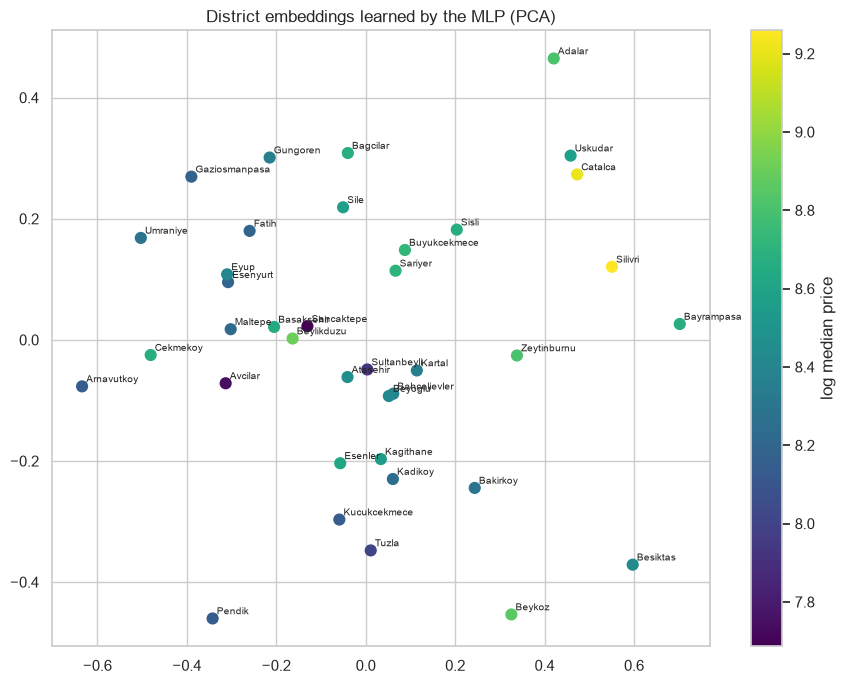

In [ ]:
# What did the district embedding learn? Project the 8-d vectors to 2-d.
from sklearn.decomposition import PCA
emb = mlp.get_layer("district_emb").get_weights()[0]
xy = PCA(2, random_state=SEED).fit_transform(emb)
med = df.groupby("neighbourhood_cleansed")["price"].median().reindex(districts)
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=np.log(med), cmap="viridis", s=60)
for (px, py), name in zip(xy, districts):
    ax.annotate(name, (px, py), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, label="log median price")
ax.set(title="District embeddings learned by the MLP (PCA)")
plt.tight_layout(); plt.savefig(FIGS / "district_embeddings.png", dpi=120); plt.show()

**What I see:** _do expensive districts cluster together without being told?_

## 7. Compare

,RMSE_log,MAE_TRY,MedianAPE_%,R2_log
XGBoost (tuned),0.308,1359.633,14.016,0.751
XGBoost,0.312,1386.085,14.785,0.745
Random Forest,0.336,1474.375,15.514,0.705
MLP (ours),0.364,1626.198,17.553,0.653
Ridge,0.431,1951.195,24.254,0.514
Baseline (median),0.575,2584.740,34.325,0.134


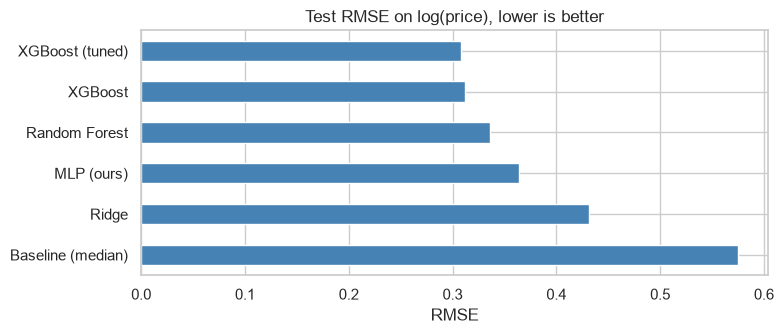

In [ ]:
res = pd.DataFrame(results).T.sort_values("RMSE_log")
display(res.round(3))
fig, ax = plt.subplots(figsize=(8, 3.5))
res["RMSE_log"].sort_values(ascending=False).plot(kind="barh", ax=ax, color="steelblue")
ax.set(title="Test RMSE on log(price), lower is better", xlabel="RMSE")
plt.tight_layout(); plt.savefig(FIGS / "model_comparison.png", dpi=120); plt.show()

best model: XGBoost (tuned)


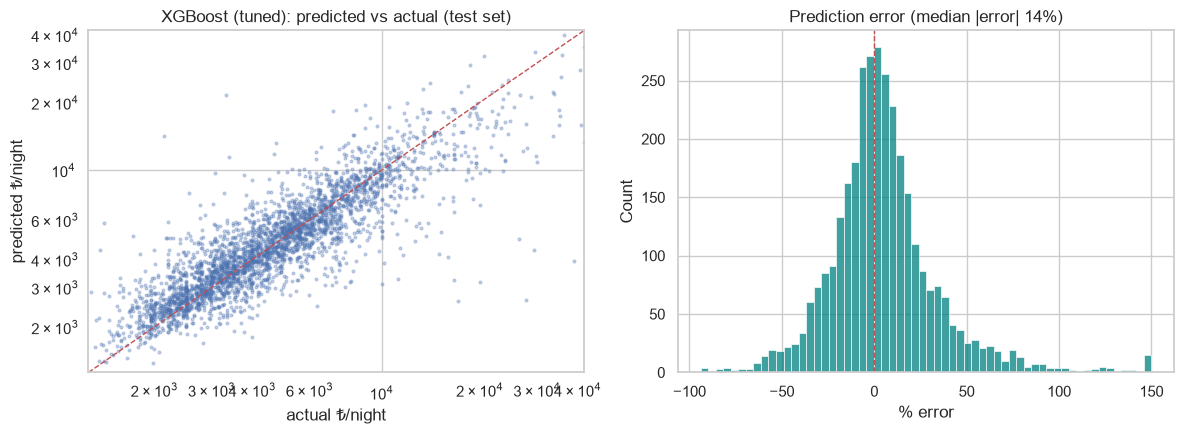

In [ ]:
# Best scikit-learn-style model by test RMSE (the MLP is compared but saved separately)
candidates = {"Ridge": ridge, "Random Forest": rf, "XGBoost": xgb_base}
if xgb_tuned is not None:
    candidates["XGBoost (tuned)"] = xgb_tuned
best_name = min(candidates, key=lambda k: results[k]["RMSE_log"])
BEST = candidates[best_name]
print("best model:", best_name)

# Predicted vs actual on the test set
pred = np.exp(np.clip(BEST.predict(X_test), LOG_MIN, LOG_MAX)); actual = np.exp(y_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(actual, pred, s=4, alpha=.3)
lim = [actual.quantile(.005), actual.quantile(.995)]
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set(xscale="log", yscale="log", xlim=lim, ylim=lim,
    title=f"{best_name}: predicted vs actual (test set)", xlabel="actual ₺/night", ylabel="predicted ₺/night")
err = (pred / actual - 1) * 100
sns.histplot(err.clip(-100, 150), bins=60, ax=ax[1], color="teal")
ax[1].axvline(0, color="r", ls="--", lw=1)
ax[1].set(title=f"Prediction error (median |error| {np.median(np.abs(err)):.0f}%)", xlabel="% error")
plt.tight_layout(); plt.savefig(FIGS / "predicted_vs_actual.png", dpi=120); plt.show()

### 5-fold cross-validation
One train/test split can be lucky or unlucky. Here every listing is used for testing exactly once, and we report the **mean ± standard deviation** of RMSE over 5 folds. (The MLP is left out: its early stopping needs its own validation set.)

Ridge              RMSE 0.434 ± 0.003
Random Forest      RMSE 0.340 ± 0.002
XGBoost            RMSE 0.308 ± 0.002
XGBoost (tuned)    RMSE 0.306 ± 0.001


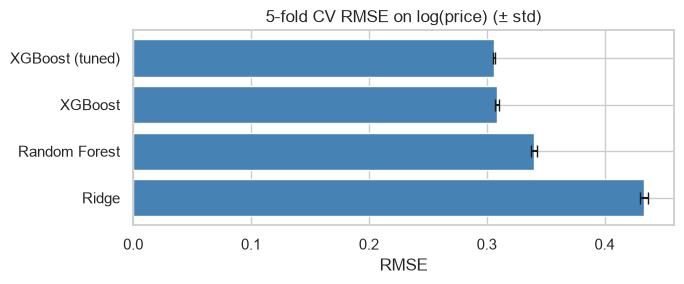

,CV_RMSE_mean,CV_RMSE_std
XGBoost (tuned),0.306,0.001
XGBoost,0.308,0.002
Random Forest,0.340,0.002
Ridge,0.434,0.003


In [ ]:
from sklearn.model_selection import cross_val_score
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = {}
for name, model in candidates.items():
    scores = -cross_val_score(model, X, y, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=1)
    cv_rows[name] = {"CV_RMSE_mean": scores.mean(), "CV_RMSE_std": scores.std()}
    print(f"{name:18s} RMSE {scores.mean():.3f} ± {scores.std():.3f}")
cv_table = pd.DataFrame(cv_rows).T.sort_values("CV_RMSE_mean")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cv_table.index, cv_table["CV_RMSE_mean"], xerr=cv_table["CV_RMSE_std"], color="steelblue", capsize=4)
ax.invert_yaxis(); ax.set(title="5-fold CV RMSE on log(price) (± std)", xlabel="RMSE")
plt.tight_layout(); plt.savefig(FIGS / "cv_comparison.png", dpi=120); plt.show()
cv_table.round(3)

**Winner and why:** _…_ (tree models usually win on tabular data; the MLP comparison is still a key slide)

## 8. SHAP: explain the XGBoost model

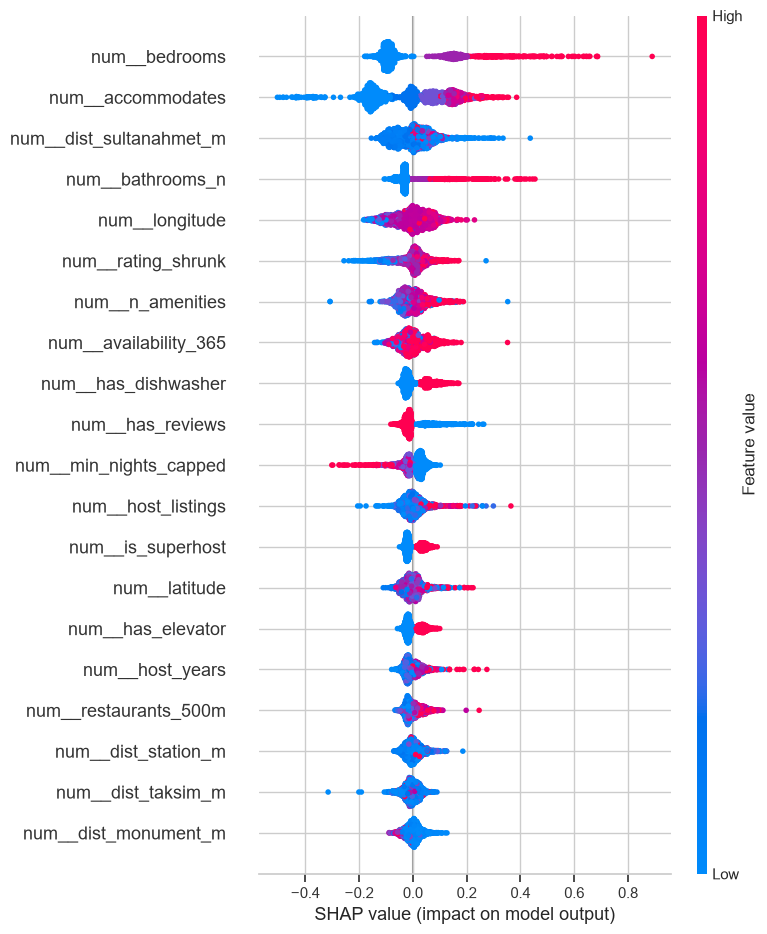

In [ ]:
import shap
xgb_best = xgb_tuned if (xgb_tuned is not None and results["XGBoost (tuned)"]["RMSE_log"] < results["XGBoost"]["RMSE_log"]) else xgb_base
pre = xgb_best.named_steps["pre"]
booster = xgb_best.named_steps["model"]
X_shap = pd.DataFrame(pre.transform(X_test), columns=pre.get_feature_names_out()).sample(2000, random_state=SEED)
try:
    shap_values = shap.TreeExplainer(booster).shap_values(X_shap)
except Exception as e:   # some shap/xgboost version pairs disagree; XGBoost can compute SHAP itself
    print("shap TreeExplainer failed, using XGBoost's built-in SHAP:", e)
    import xgboost
    shap_values = booster.get_booster().predict(xgboost.DMatrix(X_shap), pred_contribs=True)[:, :-1]
shap.summary_plot(shap_values, X_shap, max_display=20, show=False)
plt.tight_layout(); plt.savefig(FIGS / "shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

**What I see:** _top 5 drivers of price and their direction_

## 9. Fair price for every listing (out-of-fold)

If we predicted each listing with a model that was **trained on that same listing**, the prediction would be too close to its real price and every "deal" would look small. So we use **5-fold out-of-fold** predictions: each listing is priced by a model that never saw it.

Monthly-style listings (not in training) get a prediction from the final model.

In [ ]:
print("fair-price model:", best_name)   # chosen in section 7
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
oof_log = cross_val_predict(BEST, X, y, cv=kf, n_jobs=1)

final_model = BEST.fit(X, y)       # refit on all normal-stay listings, used by the app
joblib.dump(final_model, MODELS / "price_model.joblib")

df_all["fair_price"] = np.exp(np.clip(final_model.predict(df_all[CAT + NUM]), LOG_MIN, LOG_MAX))
df_all.loc[df_all["is_monthly"] == 0, "fair_price"] = np.exp(np.clip(oof_log, LOG_MIN, LOG_MAX))
df_all["price_gap"] = (df_all["fair_price"] - df_all["price"]) / df_all["fair_price"]  # + = cheaper than fair
df_all.to_parquet(PROCESSED / "listings_priced.parquet", index=False)

mlp.save(MODELS / "price_mlp.keras")
joblib.dump({"scaler": nn_scaler, "onehot": nn_onehot, "districts": districts, "y_mean": Y_MEAN, "y_std": Y_STD}, MODELS / "price_mlp_prep.joblib")
print("OOF RMSE_log:", np.sqrt(mean_squared_error(y, oof_log)).round(3))
df_all["price_gap"].describe().round(3)

fair-price model: XGBoost (tuned)
OOF RMSE_log: 0.306


count    24190.000
mean        -0.007
std          0.849
min        -31.115
25%         -0.114
50%          0.064
75%          0.278
max          0.945
Name: price_gap, dtype: float64

In [ ]:
# Best "deals": cheaper than fair, with at least some reviews
cols = ["name", "neighbourhood_cleansed", "stay_type", "price", "fair_price", "price_gap", "number_of_reviews"]
df_all[df_all["number_of_reviews"] >= 10].sort_values("price_gap", ascending=False)[cols].head(10).round(2)

,name,neighbourhood_cleansed,stay_type,price,fair_price,price_gap,number_of_reviews
765,Cheers Hostel Old City -Exclusive Dorm & Fun V...,Fatih,Entire home,2508.00,18396.27,0.86,29
14326,by Abraham Galata With Balcony 1,Beyoglu,Entire home,3323.29,21038.74,0.84,13
584,"Lovely, wooden family house in Şile",Sile,Entire home,1969.55,12152.93,0.84,28
638,2 bedroom and one saloon near SAW,Pendik,Private room,465.11,2689.48,0.83,63
5745,Cozy specious flat in Caddebostan,Kadikoy,Entire home,968.09,5589.58,0.83,11
8555,bahçe manzaralı 1+1 suit,Arnavutkoy,Hotel room,618.55,3437.71,0.82,10
977,Ev,Maltepe,Private room,487.50,2666.65,0.82,13
3431,Private Room . 15 min to Istanbul Airport.(Dou...,Arnavutkoy,Private room,433.97,2257.70,0.81,67
6169,Göztepe Metroya yakın çok uygun fiyatlı ev,Atasehir,Entire home,757.27,3661.84,0.79,28
10067,Kadıköy Art House,Kadikoy,Entire home,757.71,3613.44,0.79,20


### Summary (fill in)
- Best model: _…_ (RMSE _…_, ≈ _…_% typical error)
- MLP vs XGBoost: _…_
- Top price drivers (SHAP): _…_